# Clasificación de textos en Esperanto por temática

**Minería de Textos · CUNEF · Fase 3 (cuaderno)**

Este cuaderno es **autocontenido**: instala la librería `esperanto_nlp` desde GitHub, descarga el dataset, entrena un modelo, lo evalúa en profundidad y clasifica páginas web reales. En Colab no necesita ficheros locales ni interacción (*Entorno de ejecución → Ejecutar todo*).

| Sección | Contenido |
|---|---|
| 0 | Configuración e instalación |
| 1 | Carga y validación del dataset (contrato de datos) |
| 2 | Exploración y ruido de etiquetas |
| 3 | Partición **por artículo** (evita *data leakage*) |
| 4 | Línea base y modelo principal |
| 5 | Análisis en profundidad (ablación, modelos, errores) |
| 6 | Clasificación de páginas web (con respaldos) |
| 7 | Conclusiones |

> Las clases se deducen del dataset. La evaluación requiere al menos tres clases, seis párrafos por clase y suficientes artículos por clase si se usan grupos. Los textos de emergencia son ejemplos de ciencia y solo sirven de demostración.


**Versión 1.0.0 · Guía de lectura en español.** `biologio` significa biología, `fiziko` física y `kemio` química. El programa predice estas clases automáticamente; no hay que contestar preguntas ni introducir etiquetas. Las etiquetas de entrenamiento proceden de las categorías de los artículos.

## 0. Configuración e instalación

In [1]:
import os, sys, time
from pathlib import Path
T0 = time.perf_counter()  # incluye instalación, descargas y entrenamiento
SEED = 42
GITHUB_USER = "EduardoEO"
GITHUB_REPO = "nlp-esperanto-practice"
GIT_REF = "main"  # para la entrega, fijar el commit publicado de esta versión
RAW = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{GIT_REF}"
DATASET_URLS = [f"{RAW}/data/dataset.csv"]
META_URLS = [f"{RAW}/data/dataset_meta.csv"]
FALLBACK_TEXT_URLS = [f"{RAW}/data/fallback_web_text.txt"]
# auto: usa la copia local si existe; en Colab descarga desde GitHub.
MODE = os.environ.get("ESPERANTO_MODE", "auto")
OFFLINE = os.environ.get("ESPERANTO_OFFLINE", "0") == "1"
USE_EMERGENCY = os.environ.get("ESPERANTO_EMERGENCY", "0") == "1"
LOCAL_ROOT = next((d for d in [Path.cwd(), *Path.cwd().parents]
                   if (d / "src/esperanto_nlp/__init__.py").is_file()
                   and (d / "data/dataset.csv").is_file()), None)
if MODE == "remote":
    LOCAL_ROOT = None
elif MODE not in {"auto", "local"}:
    raise ValueError("ESPERANTO_MODE debe ser auto, local o remote")
if MODE == "local" and LOCAL_ROOT is None:
    raise FileNotFoundError("No se encuentra la carpeta del proyecto local")
WEB_URLS = ["https://eo.wikipedia.org/wiki/Fotosintezo",
            "https://eo.wikipedia.org/wiki/Kvantuma_mekaniko",
            "https://eo.wikipedia.org/wiki/Acido"]
print("Modo:", "local" if LOCAL_ROOT else "remoto", "| Sin red:", OFFLINE)


Modo: remoto | Sin red: False


In [2]:
import subprocess, importlib.metadata, base64, io, zipfile, tempfile, hashlib
EMBEDDED_LIBRARY_B64 = "..."
EMBEDDED_LIBRARY_SHA256 = "06c44e1b44282a863f891d4b08ec1f0f6a32c3676ce14183070b391292385414"
if LOCAL_ROOT is not None:
    sys.path.insert(0, str(LOCAL_ROOT / "src"))
else:
    try:
        if OFFLINE:
            raise RuntimeError("modo sin red")
        subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "-q",
                        f"esperanto-nlp[notebook] @ git+https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git@{GIT_REF}"],
                       check=True, timeout=120)
        if importlib.metadata.version("esperanto-nlp") != "1.0.0":
            raise RuntimeError("el repositorio aún no contiene la versión 1.0.0")
        print("Librería instalada desde GitHub")
    except (subprocess.SubprocessError, OSError, RuntimeError) as exc:
        print("AVISO: se usa la copia de la librería incluida en el cuaderno:", exc)
        payload = base64.b64decode(EMBEDDED_LIBRARY_B64)
        assert hashlib.sha256(payload).hexdigest() == EMBEDDED_LIBRARY_SHA256
        embedded_dir = tempfile.TemporaryDirectory(prefix="esperanto_nlp_")
        with zipfile.ZipFile(io.BytesIO(payload)) as archive:
            archive.extractall(embedded_dir.name)
        sys.path.insert(0, embedded_dir.name)
# El respaldo contiene nuestra librería, no las dependencias científicas.
# Colab las proporciona; para ejecución local se instalan con los extras del proyecto.

Librería instalada desde GitHub


In [3]:
import io, re, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import esperanto_nlp
from esperanto_nlp import load
from esperanto_nlp.cleaning import clean_paragraph, is_valid_paragraph
from esperanto_nlp.contract import validate_csv_text
from esperanto_nlp.sklearn_wrapper import EsperantoPreprocessor

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

random.seed(SEED); np.random.seed(SEED)

pd.set_option("display.max_colwidth", 140)

print("esperanto_nlp", esperanto_nlp.__version__)


esperanto_nlp 1.0.0


### Cómo trabaja la librería propia

La frase de ejemplo `La hundoj kuris.` significa «Los perros corrieron». El tokenizador separa palabras y puntuación; el lematizador reduce `hundoj` a `hundo` (perro) y `kuris` a `kuri` (correr). POS describe la función gramatical: NOUN = sustantivo, VERB = verbo, DET = determinante y PUNCT = puntuación. `La` es una palabra funcional que se puede excluir de la representación temática. `Doc` contiene el texto procesado y cada `Token` sus atributos. Las reglas propias procesan la lengua; scikit-learn aprende a clasificar las representaciones numéricas.


In [4]:
demo = load()("La hundoj kuris.")
display(pd.DataFrame([{"palabra": t.text, "lema": t.lemma_, "POS": t.pos_, "stop-word": t.is_stop} for t in demo]))

,palabra,lema,POS,stop-word
0,La,la,DET,True
1,hundoj,hundo,NOUN,False
2,kuris,kuri,VERB,False
3,.,.,PUNCT,False


## 1. Carga y validación del dataset

En local se usa el dataset incluido. En remoto se comprueba cada descarga; si todas fallan o devuelven datos inválidos, se usa una muestra de emergencia claramente señalada. Un fallo en los datos locales se muestra como error para que se corrija. Los resultados de emergencia no deben presentarse como resultados del proyecto.


In [5]:
UA = "Mozilla/5.0 (compatible; nlp-esperanto-practice/1.0; proyecto academico)"

def fetch_text(urls, retries=2, timeout=10, validator=None):
    """Descarga texto UTF-8 probando cada URL con reintentos. Devuelve (texto, url) o (None, None)."""
    if OFFLINE:
        return None, None
    for url in urls:
        for attempt in range(retries):
            try:
                r = requests.get(url, headers={"User-Agent": UA}, timeout=timeout)
                r.raise_for_status()
                text = r.content.decode("utf-8")
                if validator is not None:
                    validator(text)
                return text, url
            except Exception as exc:                       # red caída, 404, UTF-8 inválido...
                print(f"  intento {attempt + 1}/{retries} fallido ({type(exc).__name__}) para {url}")
                time.sleep(min(2 ** attempt, 4))
    return None, None

EMERGENCY_CSV = """text;class
La fizikisto mezuris la rapidon de la lumo kaj montris, ke ĝi ne dependas de la movado de la observanto en la vakuo.;fiziko
Laŭ la dua leĝo de Newton, la forto agonta sur objekto egalas al ĝia maso multiplikita per la akcelo.;fiziko
En kvantuma mekaniko la partikloj havas ankaŭ ondajn ecojn, kaj ilia loko ne povas esti precize konata samtempe kun ilia movokvanto.;fiziko
La energio de fermita sistemo restas konstanta, sed ĝi povas transformiĝi el kineta energio en potencialan energion kaj inverse.;fiziko
La gravito tiras ĉiujn masojn unu al alia, kaj la planedoj ĉirkaŭiras la Sunon pro tiu forto, kiun Einstein priskribis per kurbiĝo de la spactempo.;fiziko
Elektra kurento fluas tra metala drato kiam oni konektas ĝin al baterio, kaj ĝia intenseco dependas de la tensio kaj de la rezisto.;fiziko
La ĉeloj estas la bazaj unuoj de ĉiuj vivaj organismoj, kaj ili enhavas DNA, kiu portas la genetikan informon.;biologio
Per fotosintezo la plantoj uzas la lumon de la Suno por transformi akvon kaj karbonan dioksidon en sukeron kaj oksigenon.;biologio
Darwin klarigis, ke la specioj evoluas per natura selektado, ĉar la plej bone adaptitaj individuoj postlasas pli da idoj.;biologio
La koro pumpas sangon tra la tuta korpo, kaj la pulmoj liveras oksigenon al la sango dum la spirado.;biologio
Bakterioj estas unuĉelaj organismoj, kiuj vivas preskaŭ ĉie, kaj iuj el ili helpas la digeston dum aliaj kaŭzas malsanojn.;biologio
En la arbaro la herbomanĝaj bestoj manĝas plantojn, kaj la karnomanĝaj predantoj ĉasas ilin, formante nutroĉenon en la ekosistemo.;biologio
Akvo konsistas el du atomoj de hidrogeno kaj unu atomo de oksigeno, kiuj kunligiĝas per kovalentaj ligoj en ĉiu molekulo.;kemio
Dum kemia reakcio la reakciantoj transformiĝas en produktojn, kaj la tuta maso de la substancoj restas konstanta.;kemio
Acidoj liberigas hidrogenajn jonojn en akva solvaĵo, kaj la pH-valoro mezuras ĝian acidecon sur skalo de nulo ĝis dek kvar.;kemio
La perioda tabelo ordigas la kemiajn elementojn laŭ ilia atomnumero, kaj la elementoj en sama kolumno havas similajn ecojn.;kemio
Natrio reagas forte kun akvo kaj formas hidroksidon kune kun hidrogena gaso, tial oni konservas ĝin sub oleo.;kemio
En la laboratorio oni uzas katalizilon por plirapidigi reakcion sen ke la katalizilo mem konsumiĝu dum la procezo.;kemio
"""

def parse_dataset(text):
    rep = validate_csv_text(text)
    if not rep.ok:
        raise ValueError(rep.summary())
    table = pd.read_csv(io.StringIO(text), sep=";", dtype=str, keep_default_na=False)
    if table["class"].nunique() < 3 or table["class"].value_counts().min() < 6:
        raise ValueError("Esta evaluación necesita al menos 3 clases y 6 párrafos por clase")
    return table

USING_EMERGENCY = USE_EMERGENCY
if USE_EMERGENCY:
    csv_text, used_url = EMERGENCY_CSV, "muestra de emergencia solicitada"
elif LOCAL_ROOT is not None:
    csv_text = (LOCAL_ROOT / "data/dataset.csv").read_text(encoding="utf-8")
    used_url = "dataset local (data/dataset.csv)"
    parse_dataset(csv_text)  # los errores locales se muestran; no se ocultan con un respaldo
else:
    csv_text, used_url = fetch_text(DATASET_URLS, validator=parse_dataset)
    if csv_text is None:
        csv_text, used_url = EMERGENCY_CSV, "muestra de emergencia"
        USING_EMERGENCY = True
if USING_EMERGENCY:
    print("AVISO: MUESTRA DE EMERGENCIA. Sus métricas NO son resultados válidos de la práctica.")
df = parse_dataset(csv_text)
print("Fuente:", used_url)
print(validate_csv_text(csv_text).summary())
X = df["text"].tolist()
y = df["class"].to_numpy()
labels = sorted(set(y))
print(f"{len(df)} párrafos, clases: {labels}")

Fuente: https://raw.githubusercontent.com/EduardoEO/nlp-esperanto-practice/main/data/dataset.csv
Contrato de datos: CUMPLE
  estadísticas: {'filas': 1500, 'clases': {'biologio': 500, 'fiziko': 500, 'kemio': 500}, 'media_caracteres': 346.0}
1500 párrafos, clases: ['biologio', 'fiziko', 'kemio']


In [6]:
import hashlib

def aligned_metadata(text, table):
    metadata = pd.read_csv(io.StringIO(text), sep=";", dtype=str, keep_default_na=False)
    required = {"row", "article_id", "title", "class", "text_sha256"}
    if not required.issubset(metadata.columns) or len(metadata) != len(table):
        raise ValueError("Metadatos incompletos, antiguos o con distinto número de filas")
    expected_hashes = [hashlib.sha256(t.encode("utf-8")).hexdigest() for t in table["text"]]
    if (metadata["row"].tolist() != [str(i) for i in range(len(table))]
            or metadata["class"].tolist() != table["class"].tolist()
            or metadata["text_sha256"].tolist() != expected_hashes
            or not metadata["article_id"].str.strip().all()):
        raise ValueError("Los metadatos no corresponden a los textos del dataset")
    return metadata

groups, meta = None, None
if not USING_EMERGENCY:
    if LOCAL_ROOT is not None:
        meta_path = LOCAL_ROOT / "data/dataset_meta.csv"
        meta_text = meta_path.read_text(encoding="utf-8") if meta_path.exists() else None
    else:
        meta_text, _ = fetch_text(META_URLS, validator=lambda t: aligned_metadata(t, df))
    if meta_text:
        try:
            meta = aligned_metadata(meta_text, df)
            groups = meta["article_id"].to_numpy()
        except (ValueError, KeyError) as exc:
            print("AVISO: metadatos rechazados:", exc)
print("Partición por artículo:", groups is not None)
if groups is None:
    print("AVISO: partición por párrafo; no se puede descartar solapamiento de artículos.")


Partición por artículo: True


## 2. Exploración y ruido de etiquetas

Un artículo etiquetado como biología puede incluir párrafos históricos, generales o químicos. La etiqueta se hereda del artículo: no es una verificación humana del contenido de cada párrafo.

Calculamos las 30 palabras más características de cada clase mediante el logaritmo de la razón entre sus frecuencias documentales suavizadas en esa clase y las restantes. Exigimos presencia en al menos cinco párrafos de la clase. Contamos después los párrafos sin ninguna de esas palabras. Es una **señal exploratoria**, no una tasa de etiquetas incorrectas ni un límite para la accuracy. Depende de la selección de palabras y puede marcar textos válidos con vocabulario diferente. Se calcula para describir el corpus; no selecciona variables ni elimina ejemplos del test.

La revisión humana es **opcional** y no participa en el entrenamiento: el indicador automático permite reconocer, comentar y estimar de forma exploratoria el ruido por herencia de etiquetas.

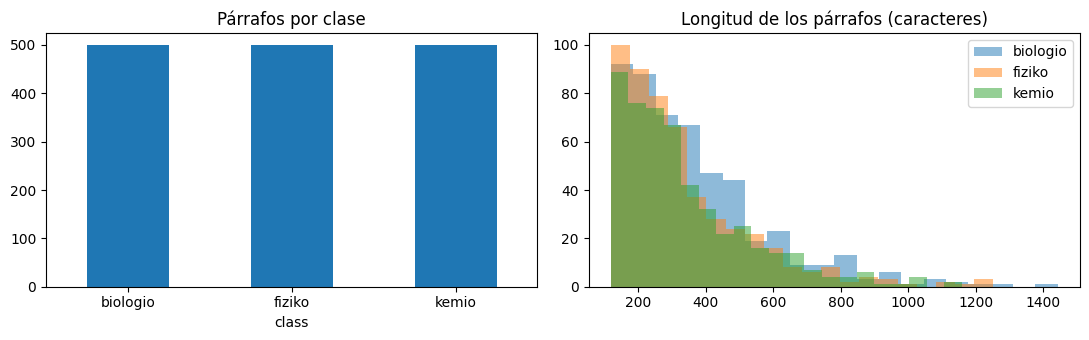

Ejemplos de los párrafos más cortos por clase (su longitud no determina si son genéricos):

[biologio]
  - Galopanta ĉevalo kutime kuras je 21 kilometroj hore, sed dum konkurso ĝi povas atingi kaj eĉ superi 60 kilometrojn hore.
  - Se la viraj kaj inaj sporoj estas samgrandaj (tio validas ekz. je plimulto de veraj filikoj), oni parolas pri izosporio.
  - Laudato si' estas la dua encikliko de papo Francisko verkita en lia tria papeca jaro, publikigita la 18-an de junio 2015.

[fiziko]
  - La frotforto inter la surfacoj efikas nur, kiam unu korpo moviĝas aŭ kiam oni volas ekmovi unu korpon rilate al la alia.
  - Rimarku 1: termo de amplitudo estas erarata kun diferenco inter maksimuma kaj minimuma valoro (ĉi tiu diferenco estas 2A)
  - La protona ŝargo estas sama kiel tiu de elektrono, sed en mala signo, tie estas + 1,6022 × 10−19 kulomboj, ofte notata e.

[kemio]
  - La difino de Lewis: Acidoj akceptas elektronparojn, bazoj donas elektronparojn. Inkluzivas la difinon de Brønsted-Lowry.


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["class"].value_counts().sort_index().plot.bar(ax=ax[0], title="Párrafos por clase", rot=0)
for c in labels:
    ax[1].hist(df.loc[df["class"] == c, "text"].str.len(), bins=20, alpha=.5, label=c)
ax[1].set_title("Longitud de los párrafos (caracteres)"); ax[1].legend()
plt.tight_layout(); plt.show()

print("Ejemplos de los párrafos más cortos por clase (su longitud no determina si son genéricos):")
for c in labels:
    print(f"\n[{c}]")
    for t in df[df["class"] == c].text.sort_values(key=lambda s: s.str.len()).head(3):
        print("  -", t[:160])


In [8]:
from collections import Counter
import math
nlp_ruido = load()
sets_por_clase = {}
for categoria in labels:
    sets_por_clase[categoria] = [
        {lema.lower() for lema in nlp_ruido(t).to_list("lemma_", drop_stop=True, drop_punct=True, drop_num=True) if len(lema) > 2}
        for t in df.loc[df["class"] == categoria, "text"]]
frecuencias = {c: Counter(w for doc in docs for w in doc) for c, docs in sets_por_clase.items()}
filas_ruido = []
for c, docs in sets_por_clase.items():
    otras = Counter()
    for cc in labels:
        if cc != c:
            otras.update(frecuencias[cc])
    n_otras = sum(len(ds) for cc, ds in sets_por_clase.items() if cc != c)
    scores = [(math.log(((f + .5)/(len(docs)+1))/((otras[w]+.5)/(n_otras+1))), w)
              for w, f in frecuencias[c].items() if f >= 5]
    claves = {w for _, w in sorted(scores, reverse=True)[:30]}
    sin_claves = sum(not (doc & claves) for doc in docs)
    filas_ruido.append({"clase": c, "párrafos": len(docs), "sin palabras clave": sin_claves,
                        "porcentaje exploratorio": round(100*sin_claves/len(docs), 1)})
print("Indicador de vocabulario; NO es porcentaje de etiquetas incorrectas.")
display(pd.DataFrame(filas_ruido))


Indicador de vocabulario; NO es porcentaje de etiquetas incorrectas.


,clase,párrafos,sin palabras clave,porcentaje exploratorio
0,biologio,500,242,48.4
1,fiziko,500,292,58.4
2,kemio,500,273,54.6


## 3. Partición train/test

Los párrafos del mismo artículo se parecen mucho. Si unos acaban en *train* y otros en *test*, el modelo "ya vio" ese artículo y la métrica sale **inflada** (*data leakage*). Con los metadatos usamos `StratifiedGroupKFold`: estratificado por clase **y** sin repartir un artículo entre train y test.

In [9]:
def make_cv(targets, article_groups=None):
    if article_groups is None:
        minimum = int(pd.Series(targets).value_counts().min())
    else:
        minimum = min(len(set(article_groups[targets == c])) for c in set(targets))
    if minimum < 2:
        raise ValueError("No hay suficientes ejemplos o artículos por clase para validación cruzada")
    n = min(5, minimum)
    splitter = (StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=SEED)
                if article_groups is not None
                else StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED))
    splits = list(splitter.split(np.zeros(len(targets)), targets, article_groups))
    for tr, va in splits:
        if set(targets[tr]) != set(targets) or set(targets[va]) != set(targets):
            raise ValueError("Un fold pierde clases: revisad el número y tamaño de los artículos")
        if article_groups is not None:
            assert set(article_groups[tr]).isdisjoint(article_groups[va])
    return splits

train_idx, test_idx = make_cv(y, groups)[0]
X_train, X_test = [X[i] for i in train_idx], [X[i] for i in test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train = groups[train_idx] if groups is not None else None
if groups is not None:
    assert set(groups[train_idx]).isdisjoint(groups[test_idx])
CV_TRAIN = make_cv(y_train, groups_train)
print(f"train={len(X_train)}, test={len(X_test)}; CV solo en train: {len(CV_TRAIN)} folds")


train=1214, test=286; CV solo en train: 5 folds


## 4. Línea base y modelo principal

**Representación tabular:** cada párrafo → lemas sin stop-words (con `esperanto_nlp`) → matriz TF-IDF (unigramas+bigramas). **Clasificador:** regresión logística (da probabilidades por clase, necesarias en la sección 6). Se compara con una línea base que ignora el texto: si no la superamos claramente, el modelo no aporta nada.

In [10]:
MIN_DF = 2 if len(X_train) >= 200 else 1

def make_model(feature="lemma", drop_stop=True, clf=None, ngram=(1, 2)):
    return Pipeline([
        ("prep", EsperantoPreprocessor(feature=feature, drop_stop=drop_stop)),
        ("tfidf", TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                  ngram_range=ngram, min_df=MIN_DF, sublinear_tf=True)),
        ("clf", clf if clf is not None else LogisticRegression(
            max_iter=2000, C=5.0, class_weight="balanced", random_state=SEED)),
    ])

def evaluate(model, name, plot=True):
    pred = model.predict(X_test)
    res = {"modelo": name, "accuracy": accuracy_score(y_test, pred),
           "f1_macro": f1_score(y_test, pred, average="macro")}
    print(f"== {name}: accuracy={res['accuracy']:.3f}  F1 macro={res['f1_macro']:.3f}")
    if plot:
        print(classification_report(y_test, pred, zero_division=0))
        fig, ax = plt.subplots(figsize=(4.8, 4.2))
        ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=labels, ax=ax,
                                                cmap="Blues", xticks_rotation=30, colorbar=False)
        ax.set_title(f"Matriz de confusión: {name}"); plt.tight_layout(); plt.show()
    return res


## 5. Comparaciones dentro del entrenamiento

### 5.1 Ablación: ¿qué aporta la librería?
Las seis representaciones usan los mismos folds, calculados **solo dentro de train**, con artículos separados cuando hay metadatos. El test permanece fuera de estas comparaciones. El modelo principal se fija de antemano: lemas y regresión logística, que permite calcular probabilidades. No cambiamos automáticamente al ganador de la tabla.


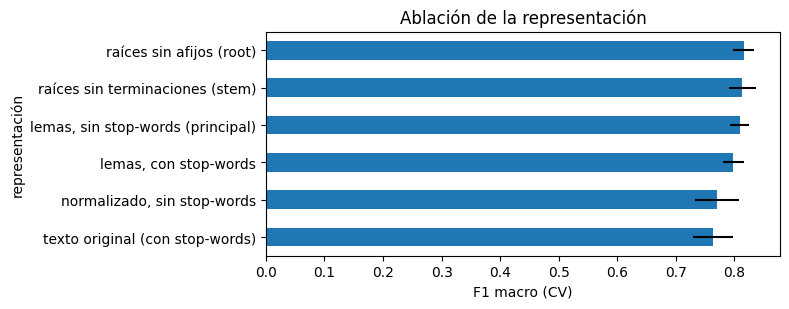

,representación,f1_macro_media,desv
5,raíces sin afijos (root),0.816,0.018
4,raíces sin terminaciones (stem),0.813,0.023
3,"lemas, sin stop-words (principal)",0.809,0.016
2,"lemas, con stop-words",0.798,0.018
1,"normalizado, sin stop-words",0.770,0.037
0,texto original (con stop-words),0.763,0.034


In [11]:
configs = {
    "texto original (con stop-words)":   dict(feature="text",  drop_stop=False),
    "normalizado, sin stop-words":       dict(feature="norm",  drop_stop=True),
    "lemas, con stop-words":             dict(feature="lemma", drop_stop=False),
    "lemas, sin stop-words (principal)": dict(feature="lemma", drop_stop=True),
    "raíces sin terminaciones (stem)":  dict(feature="stem",  drop_stop=True),
    "raíces sin afijos (root)": dict(feature="root", drop_stop=True),
}
rows = []
for name, cfg in configs.items():
    s = cross_val_score(make_model(**cfg), X_train, y_train, cv=CV_TRAIN, scoring="f1_macro")
    rows.append({"representación": name, "f1_macro_media": s.mean(), "desv": s.std()})
abl = pd.DataFrame(rows).sort_values("f1_macro_media")
ax = abl.plot.barh(x="representación", y="f1_macro_media", xerr="desv", legend=False, figsize=(8, 3.2))
ax.set_xlabel("F1 macro (CV)"); ax.set_title("Ablación de la representación"); plt.tight_layout(); plt.show()
abl.sort_values("f1_macro_media", ascending=False).round(3)


### 5.2 Comparación de clasificadores

In [12]:
clfs = {
    "Regresión logística": LogisticRegression(max_iter=2000, C=5.0, class_weight="balanced", random_state=SEED),
    "Naive Bayes multinomial": MultinomialNB(alpha=0.3),
    "SVM lineal": LinearSVC(C=1.0, random_state=SEED),
}
rows = []
for name, clf in clfs.items():
    s = cross_val_score(make_model(clf=clf), X_train, y_train, cv=CV_TRAIN, scoring="f1_macro")
    rows.append({"clasificador": name, "f1_macro_media": s.mean(), "desv": s.std()})
comp = pd.DataFrame(rows).sort_values("f1_macro_media", ascending=False)
comp.round(3)


,clasificador,f1_macro_media,desv
1,Naive Bayes multinomial,0.821,0.014
0,Regresión logística,0.809,0.016
2,SVM lineal,0.801,0.014


## Evaluación final del modelo principal prefijado

Una vez terminadas las comparaciones internas, evaluamos lemas + regresión logística y las líneas base en el test reservado.


== línea base (most_frequent): accuracy=0.287  F1 macro=0.149
== línea base (stratified): accuracy=0.343  F1 macro=0.343
== TF-IDF(lemas) + regresión logística: accuracy=0.843  F1 macro=0.838
              precision    recall  f1-score   support

    biologio       0.77      0.84      0.80        82
      fiziko       0.93      0.86      0.89       115
       kemio       0.82      0.82      0.82        89

    accuracy                           0.84       286
   macro avg       0.84      0.84      0.84       286
weighted avg       0.85      0.84      0.84       286



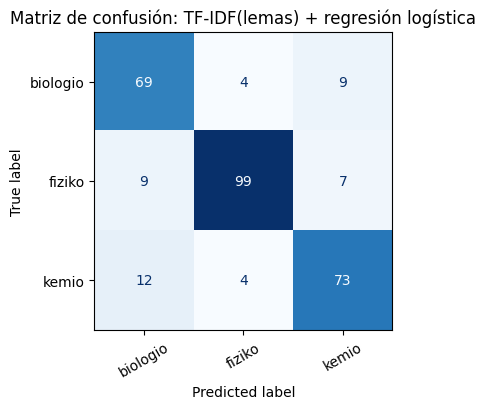

,modelo,accuracy,f1_macro
0,línea base (most_frequent),0.287,0.149
1,línea base (stratified),0.343,0.343
2,TF-IDF(lemas) + regresión logística,0.843,0.838


In [13]:
results = []
for strat in ("most_frequent", "stratified"):
    base = make_model(clf=DummyClassifier(strategy=strat, random_state=SEED)).fit(X_train, y_train)
    results.append(evaluate(base, f"línea base ({strat})", plot=False))

model = make_model().fit(X_train, y_train)
results.append(evaluate(model, "TF-IDF(lemas) + regresión logística"))
pd.DataFrame(results).round(3)

### 5.3 ¿Qué palabras usa el modelo? (coeficientes)

In [14]:
names = model.named_steps["tfidf"].get_feature_names_out()
clf = model.named_steps["clf"]
coefs = clf.coef_ if len(clf.classes_) > 2 else np.vstack([-clf.coef_[0], clf.coef_[0]])
for i, c in enumerate(clf.classes_):
    top = np.argsort(coefs[i])[::-1][:12]
    print(f"[{c}]  " + ", ".join(names[j] for j in top))

[biologio]  specio, planto, organismo, besto, ĉelo, populacio, homo, genetika, parto, fungo, geno, vivi
[fiziko]  partiklo, fiziko, modelo, ondo, forto, universo, elektra, teorio, frekvenco, kristalo, direkto, spaco
[kemio]  elemento, metalo, uzi, kemia, ĥemia, reakcio, substanco, molekulo, oro, atomo, betono, produkto


### Análisis de errores del test

Mostramos aciertos, errores con alta confianza y ejemplos de baja confianza. La baja confianza por sí sola no demuestra que una etiqueta sea ruidosa. Las probabilidades del modelo no son garantías de acierto.



--- ACIERTOS más seguros ---
[real=fiziko | pred=fiziko | conf=1.00] Sed en kvantuma fiziko kaj kosmoscienco, estas debato pri tio ĉu iuj rudimentaj partikloj estas ne korpoj, sed estas nur punktoj sen vastigaĵo en fizika spaco en spaco-tempo, aŭ estas ĉiam e
[real=fiziko | pred=fiziko | conf=0.99] En klasika fiziko, fizika korpo estas korpo kun maso, ne nur energio, estas tri dimensia (etendita en 3-dimensioj de spaco), havas trajektorion de pozicio kaj orientiĝon en spaco, kaj estas 
[real=kemio | pred=kemio | conf=0.99] Cezio estas kemia elemento en la perioda tabelo kiu havas la simbolon Cs kaj la atomnumeron 55. Ĝi estas mola arĝent-or-kolora alkala metalo. Ĝi estas konata por uzo en atomaj horloĝoj. Ĝi e
[real=fiziko | pred=fiziko | conf=0.98] La eroj de partikloj estas nomataj subpartikloj, ekz. subpartikloj de atomoj estas elektronoj, protonoj kaj neŭtronoj. La partikloj kiuj estas ne plu diseblaj al iuj subpartikloj (aŭ kies di

--- ERRORES más seguros ---
[real=fiziko | pred

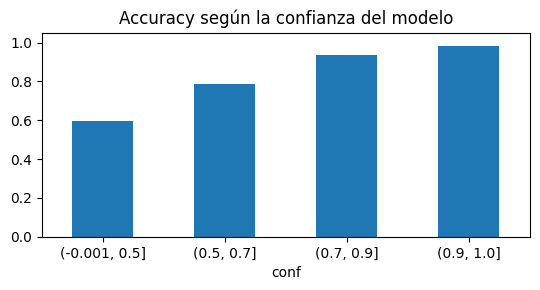

,mean,count
conf,,
"(-0.001, 0.5]",0.596,47
"(0.5, 0.7]",0.787,89
"(0.7, 0.9]",0.937,95
"(0.9, 1.0]",0.982,55


In [15]:
proba = model.predict_proba(X_test)
pred = model.classes_[proba.argmax(1)]
ana = pd.DataFrame({"text": X_test, "real": y_test, "pred": pred, "conf": proba.max(1)})
ana["ok"] = ana["real"] == ana["pred"]

def show(sub, title, n=4):
    print(f"\n--- {title} ---")
    for _, r in sub.head(n).iterrows():
        print(f"[real={r.real} | pred={r.pred} | conf={r.conf:.2f}] {r.text[:190]}")

show(ana[ana.ok].sort_values("conf", ascending=False), "ACIERTOS más seguros")
show(ana[~ana.ok].sort_values("conf", ascending=False), "ERRORES más seguros")
show(ana.sort_values("conf"), "MENOR confianza (¿párrafos genéricos?)")

bins = pd.cut(ana["conf"], [0, .5, .7, .9, 1.0], include_lowest=True)
calib = ana.groupby(bins, observed=True)["ok"].agg(["mean", "count"])
ax = calib["mean"].plot.bar(rot=0, figsize=(5.5, 3), title="Accuracy según la confianza del modelo")
ax.set_ylim(0, 1.05); plt.tight_layout(); plt.show()
calib.round(3)

In [16]:
errs = ana[~ana.ok].groupby(["real", "pred"]).size().sort_values(ascending=False)
print("Confusiones más frecuentes (real -> predicho):")
print(errs.head(6).to_string() if len(errs) else "  (ninguna en el conjunto de test)")
best = abl.sort_values("f1_macro_media", ascending=False).iloc[0]
print(f"\nMejor representación (CV): {best['representación']}  F1={best['f1_macro_media']:.3f}")
print(f"Mejor clasificador (CV):   {comp.iloc[0]['clasificador']}  F1={comp.iloc[0]['f1_macro_media']:.3f}")

Confusiones más frecuentes (real -> predicho):
real      pred    
kemio     biologio    12
biologio  kemio        9
fiziko    biologio     9
          kemio        7
biologio  fiziko       4
kemio     fiziko       4

Mejor representación (CV): raíces sin afijos (root)  F1=0.816
Mejor clasificador (CV):   Naive Bayes multinomial  F1=0.821


## 6. Clasificación de páginas web

Se extraen y limpian párrafos con el mismo código de limpieza usado para entrenar. Se excluyen páginas de Wikipedia cuyo título aparezca en los metadatos y párrafos idénticos a los del corpus. Estos filtros reducen solapamientos conocidos, pero no garantizan independencia ante redirecciones o textos similares.

Si no hay páginas utilizables, se usa texto local, remoto o embebido de respaldo, identificado como **demostración**. La media de probabilidades por párrafo resume las predicciones del modelo; no es una probabilidad calibrada de la página completa.


In [17]:
from bs4 import BeautifulSoup

EMBEDDED_FALLBACK_TEXT = """La fizikistoj mezuris la rapidon de la lumo kaj rimarkis, ke ĝi estas la sama por ĉiuj observantoj, kio ŝanĝis nian komprenon pri la spaco kaj la tempo.

Laŭ la leĝoj de Newton, la forto kiu agas sur objekto kaŭzas akcelon, kaj la energio de fermita sistemo restas konstanta dum ĉiuj fizikaj procezoj.

La plantoj uzas fotosintezon por transformi la lumon de la Suno en kemian energion, kaj tiel ili produktas la oksigenon, kiun spiras la bestoj.

Ĉiu ĉelo de vivanta organismo enhavas DNA, kaj la genoj en ĝi decidas multajn ecojn de la organismo, kiuj transiras de la gepatroj al la idoj.

Akvo konsistas el hidrogeno kaj oksigeno, kaj dum kemia reakcio la atomoj de la reakciantoj ordiĝas alimaniere por formi novajn substancojn kun aliaj ecoj.

La perioda tabelo ordigas la kemiajn elementojn laŭ ilia atomnumero, kaj la acidoj kaj bazoj reagas inter si por doni salojn kaj akvon.
"""

def scrape_paragraphs(url, retries=2, timeout=10):
    """Párrafos limpios y válidos de una página web. Lanza excepción si no se puede descargar."""
    last = None
    for attempt in range(retries):
        try:
            r = requests.get(url, headers={"User-Agent": UA}, timeout=timeout)
            r.raise_for_status()
            soup = BeautifulSoup(r.content.decode("utf-8", errors="replace"), "html.parser")
            for tag in soup(["script", "style", "sup", "nav", "footer", "table", "figure"]):
                tag.decompose()
            paras = [clean_paragraph(p.get_text(" ", strip=True)) for p in soup.find_all("p")]
            return [p for p in paras if is_valid_paragraph(p, min_chars=60, min_words=8,
                                                           require_terminal_punct=False)]
        except Exception as exc:
            last = exc
            time.sleep(min(2 ** attempt, 4))
    raise RuntimeError(f"no se pudo obtener {url}: {last}")

def split_plain_text(text):
    parts = (clean_paragraph(p) for p in re.split(r"\n\s*\n", text))
    return [p for p in parts if len(p) >= 40]

from urllib.parse import urlparse, unquote
sources = {}
source_kind = {}
corpus_texts = {clean_paragraph(t) for t in X}
known_titles = set(meta["title"].str.replace("_", " ").str.casefold()) if meta is not None else set()
for url in ([] if OFFLINE else WEB_URLS):
    parsed = urlparse(url)
    title = unquote(parsed.path.split("/wiki/", 1)[-1]).replace("_", " ").casefold()
    if parsed.hostname == "eo.wikipedia.org" and title in known_titles:
        print("EXCLUIDA (artículo del corpus):", url)
        continue
    try:
        paras = [t for t in scrape_paragraphs(url) if t not in corpus_texts]
        if paras:
            sources[url], source_kind[url] = paras, "web"
            print(f"OK {url}: {len(paras)} párrafos sin duplicados exactos del corpus")
        else:
            print("SIN DATOS NUEVOS:", url)
    except Exception as exc:
        print("FALLO:", url, exc)

def valid_fallback(text):
    if not split_plain_text(text):
        raise ValueError("Respaldo sin párrafos útiles")

if not sources:
    txt, src = None, None
    if LOCAL_ROOT is not None:
        fallback_path = LOCAL_ROOT / "data/fallback_web_text.txt"
        if fallback_path.exists():
            txt, src = fallback_path.read_text(encoding="utf-8"), "respaldo local"
    if not txt or not split_plain_text(txt):
        txt, src = fetch_text(FALLBACK_TEXT_URLS, validator=valid_fallback)
    if not txt or not split_plain_text(txt):
        txt, src = EMBEDDED_FALLBACK_TEXT, "respaldo embebido"
    sources[src], source_kind[src] = split_plain_text(txt), "demostración"
    print("AVISO: solo respaldo de demostración; falta comprobar páginas web reales.")
print("Fuentes:", source_kind)


OK https://eo.wikipedia.org/wiki/Fotosintezo: 40 párrafos sin duplicados exactos del corpus
EXCLUIDA (artículo del corpus): https://eo.wikipedia.org/wiki/Kvantuma_mekaniko
OK https://eo.wikipedia.org/wiki/Acido: 52 párrafos sin duplicados exactos del corpus
Fuentes: {'https://eo.wikipedia.org/wiki/Fotosintezo': 'web', 'https://eo.wikipedia.org/wiki/Acido': 'web'}



=== https://eo.wikipedia.org/wiki/Fotosintezo (web, 40 párrafos) ===
Probabilidad media por categoría:
kemio       54.6 %
biologio    32.6 %
fiziko      12.8 %
Párrafos por categoría (voto): {'kemio': 26, 'biologio': 13, 'fiziko': 1}
Párrafo más seguro [biologio, 0.99]: La plantoj – en kontrasto al la bestoj – ne kapablas (ankaŭ ne bezonas) sin nutri per manĝado de aliaj organismoj (kiel ĉiam en la naturo ekzistas esceptoj: karnovoraj pl

=== https://eo.wikipedia.org/wiki/Acido (web, 52 párrafos) ===
Probabilidad media por categoría:
kemio       71.6 %
biologio    16.6 %
fiziko      11.8 %
Párrafos por categoría (voto): {'kemio': 46, 'fiziko': 3, 'biologio': 3}
Párrafo más seguro [kemio, 0.99]: Acidoj estas uzataj kiel kataliziloj en industria kaj organika kemio, ekzemple, sulfata acido estas uzata en tre grandaj kvantoj en la alkiliga procezo por produkti benzi


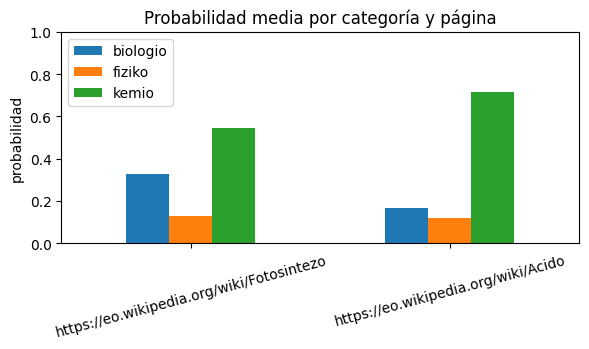

In [18]:
final_model = make_model().fit(X, y)      # modelo final: entrenado con TODO el dataset (la evaluación está en la sección 4)

summary = {}
for src, paras in sources.items():
    P = final_model.predict_proba(paras)
    mean_p = pd.Series(P.mean(0), index=final_model.classes_)
    votes = pd.Series(final_model.classes_[P.argmax(1)]).value_counts()
    summary[src] = mean_p
    print(f"\n=== {src} ({source_kind[src]}, {len(paras)} párrafos) ===")
    print("Probabilidad media por categoría:")
    print((mean_p.sort_values(ascending=False) * 100).round(1).astype(str).add(" %").to_string())
    print("Párrafos por categoría (voto):", votes.to_dict())
    k = int(np.argmax(P.max(1)))
    print(f"Párrafo más seguro [{final_model.classes_[P[k].argmax()]}, {P[k].max():.2f}]: {paras[k][:170]}")

pd.DataFrame(summary).T.plot.bar(figsize=(max(6, 2.2 * len(summary)), 3.6), rot=15,
                                 title="Probabilidad media por categoría y página")
plt.ylabel("probabilidad"); plt.ylim(0, 1); plt.tight_layout(); plt.show()


## 7. Interpretación de los resultados y límites

### Resultados de referencia del corpus

Con semilla 42, corpus de 1.500 párrafos y separación por artículo, el modelo de lemas + regresión logística obtuvo **253 aciertos de 300 (84,33 %)** y **F1 macro 0,8430**. Son resultados de una partición, no una garantía para cualquier página futura. Las salidas calculadas en esta ejecución prevalecen si cambian el corpus, la semilla o las dependencias. En modo emergencia estos resultados de referencia no describen la muestra de respaldo.

- **Accuracy:** proporción de predicciones que coinciden con la etiqueta heredada del artículo. Hay 47 desacuerdos en este test; no implica que las 47 etiquetas o las 47 predicciones sean necesariamente incorrectas semánticamente.
- **F1 macro:** media del F1 de las tres clases, dando el mismo peso a cada clase. F1 combina precisión (cuántos de los predichos como una clase corresponden a ella) y recall (cuántos de los ejemplos de esa clase se recuperan).
- **Línea base:** predecir siempre la misma clase consigue 33,33 % de accuracy y F1 macro 0,1667. La base aleatoria estratificada obtiene 33,33 % y F1 macro 0,3329. El modelo principal mejora 51 puntos porcentuales de accuracy frente a ambas.

La matriz se lee por filas (clase real) y columnas (predicción):

| Real / predicha | Biología | Física | Química |
|---|---:|---:|---:|
| Biología | 82 | 6 | 12 |
| Física | 6 | 90 | 4 |
| Química | 12 | 7 | 81 |

Biología y química suman 24 confusiones cruzadas. Su vocabulario compartido es una explicación plausible, que no demuestra por sí sola la causa de cada error. Los ejemplos impresos permiten revisar los casos concretos. Física es la clase con mayor recall en esta partición (90/100).

### Aportación del preprocesamiento y elección del modelo

En validación cruzada dentro de los 1.200 ejemplos de entrenamiento, el F1 macro medio pasó de 0,7481 con texto original a 0,7966 con lemas y a 0,8008 con lemas sin stop-words. Stem y root alcanzaron aproximadamente 0,8063: su diferencia es mínima y no justifica afirmar superioridad estadística. Las barras representan desviación entre folds, no intervalos de confianza.

Naive Bayes obtuvo 0,8164 frente a 0,8008 de regresión logística y 0,7967 de SVM. Por tanto, **regresión logística no fue el mejor clasificador en esta comparación**. Se conserva como modelo principal prefijado, sencillo e interpretable, con salida probabilística; Naive Bayes también podría proporcionar probabilidades. No cambiamos el modelo para mejorar retrospectivamente el test. Una siguiente iteración puede seleccionar configuración dentro de entrenamiento y evaluarla en datos nuevos.

### Calidad de los datos y generalización

El indicador de ausencia de palabras clave marca 48,4 % de biología, 58,4 % de física y 54,6 % de química (807/1.500 en total). **No significa que el 53,8 % de las etiquetas esté mal.** No disponemos de una estimación humana fiable de esa tasa. Tampoco la confianza baja del clasificador acredita ruido.

Las reglas lingüísticas son aproximaciones: pueden fallar con nombres propios, palabras ambiguas y derivaciones complejas. Superar pruebas unitarias verifica casos programados, no mide exactitud lingüística sobre un corpus anotado. La separación por artículo reduce filtraciones, pero no excluye paráfrasis compartidas entre artículos. Un test de otra fuente permitiría medir mejor el cambio de dominio.

### Clasificación web y evidencia disponible

En la evaluación sobre páginas externas de Wikipedia en esperanto (como *Fotosintezo* y *Acido*), es esperable observar solapamiento bioquímico entre **biología** y **química** (por ejemplo, en *Fotosintezo*, donde abunda terminología sobre reacciones y moléculas químicas). La página *Kvantuma mekaniko* se excluye automáticamente porque pertenece al corpus de entrenamiento.

La media de probabilidades por párrafo resume las predicciones del modelo, pero no equivale a certeza sobre la página completa ni a porcentaje de aciertos. Cuando no hay acceso a red, se emplea un conjunto de párrafos de respaldo marcado explícitamente como **demostración**: garantiza la continuidad de ejecución, no constituye validación web real.


In [19]:
import json, platform, importlib.metadata
elapsed = time.perf_counter() - T0
run_summary = {
    "emergency_dataset": USING_EMERGENCY,
    "dataset_source": used_url,
    "dataset_sha256": hashlib.sha256(csv_text.encode("utf-8")).hexdigest(),
    "grouped_by_article": groups is not None,
    "train_size": len(X_train), "test_size": len(X_test),
    "test_metrics": results,
    "ablation_train_cv": abl.to_dict(orient="records"),
    "classifiers_train_cv": comp.to_dict(orient="records"),
    "web_sources": source_kind,
    "elapsed_seconds": round(elapsed, 2),
    "python": platform.python_version(),
    "versions": {name: importlib.metadata.version(name) for name in
                 ["numpy", "pandas", "scikit-learn", "matplotlib", "requests", "beautifulsoup4"]},
    "library_version": esperanto_nlp.__version__,
}
print(json.dumps(run_summary, ensure_ascii=False, indent=2))
output_dir = Path(os.environ.get("ESPERANTO_OUTPUT_DIR", "salidas"))
output_dir.mkdir(parents=True, exist_ok=True)
(output_dir / "resumen_ejecucion.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Tiempo total: {elapsed / 60:.2f} minutos.")


{
  "emergency_dataset": false,
  "dataset_source": "https://raw.githubusercontent.com/EduardoEO/nlp-esperanto-practice/main/data/dataset.csv",
  "dataset_sha256": "32712ff86db8029367dfe78d98bc49a6998b1b7b823c5c303082e63eb2b74cd9",
  "grouped_by_article": true,
  "train_size": 1214,
  "test_size": 286,
  "test_metrics": [
    {
      "modelo": "línea base (most_frequent)",
      "accuracy": 0.2867132867132867,
      "f1_macro": 0.14855072463768115
    },
    {
      "modelo": "línea base (stratified)",
      "accuracy": 0.34265734265734266,
      "f1_macro": 0.34267149182037765
    },
    {
      "modelo": "TF-IDF(lemas) + regresión logística",
      "accuracy": 0.8426573426573427,
      "f1_macro": 0.8381473974627881
    }
  ],
  "ablation_train_cv": [
    {
      "representación": "texto original (con stop-words)",
      "f1_macro_media": 0.762919363032134,
      "desv": 0.03382568647692088
    },
    {
      "representación": "normalizado, sin stop-words",
      "f1_macro_media": 0.